# Primary protocol: nominal A1 -> attacked A2

How do **supervised** (process prediction) and **unsupervised** detectors
compare on **unseen** SWaT attacks, and do **classical** and **deep** models
differ? Fit, select and calibrate on the nominal A1 stream; test once on A2.

Numbers here are read from the results file written by `src/protocol.py`
(the single source of truth). This notebook only loads, tabulates and plots.
Run the protocol first:

```
python src/protocol.py --save-scores
```

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from config import RESULTS
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

path = sorted(RESULTS.glob("swat-a1a2-shared-*.json"), key=lambda p: p.stat().st_mtime)[-1]
res = json.loads(path.read_text())
print("results file:", path.name, "|", len(res["runs"]), "runs,", len(res["failures"]), "failures")

results file: swat-a1a2-shared-20261025-143942.json | 16 runs, 0 failures


## 1. Data and partitions (checked on every run)

In [2]:
rep = res["data_report"]
streams = pd.DataFrame([rep["A1"], rep["A2"]]).set_index("stream")
display(streams)
display(pd.DataFrame(rep["boundaries"]).T)
print("dropped (constant in A1-fit):", rep["preprocessor"]["dropped_constant_in_fit"])

,rows,start,end,cadence_s_mode,gaps_not_1s,duplicate_timestamps,missing_values,attack_rows,n_features,source
stream,,,,,,,,,,
A1,495000,2015-12-22 16:30:00,2015-12-28 09:59:59,1.0,0,0,0,0,51,swat/SWaT_Dataset_Normal_v0.xlsx
A2,449919,2015-12-28 10:00:00,2016-01-02 14:59:59,1.0,1,0,0,54621,51,../../swat-preprocess/data/swat-2015-data.csv


,rows,start,end
fit,297000,2015-12-22 16:30:00,2015-12-26 02:59:59
val,99000,2015-12-26 03:00:00,2015-12-27 06:29:59
cal,99000,2015-12-27 06:30:00,2015-12-28 09:59:59
test,449919,2015-12-28 10:00:00,2016-01-02 14:59:59


dropped (constant in A1-fit): ['P102', 'P201', 'P202', 'P204', 'P206', 'P401', 'P403', 'P404', 'P502', 'P601', 'P603']


## 2. Primary table

`det` = attacks detected out of 35 annotated A2 intervals, at each operating
point. `FA/h` = alarm events per hour of attack-free A2 time that overlap no
attack. `duty` = share of attack-free A2 seconds under alarm -- read it next
to `det`: a detector that alarms all the time "detects" everything.
`cal/h` = the alarm rate the threshold achieved on A1 calibration.

In [3]:
rows = []
for r in res["runs"]:
    d = r["detector"]
    row = {"model": r["key"], "objective": d["objective"], "family": d["family"],
           "AP": r["average_precision"], "ROC": r["roc_auc"]}
    for op in ("budget_0.1", "budget_0.5", "q995_fit", "ksigma_cal"):
        o = r["operating_points"][op]
        row[(op, "det")] = o["detected"]
        row[(op, "FA/h")] = o["false_alarm_events_per_normal_hour"]
        row[(op, "duty")] = o["normal_duty"]
        row[(op, "cal/h")] = o["calibration_load"]["events_per_hour"]
        row[(op, "delay_s")] = o["median_delay_s"]
    rows.append(row)
table = pd.DataFrame(rows).set_index(["objective", "family", "model"]).sort_index()
table.round(3)

AP    ROC  (budget_0.1, det)  (budget_0.1, FA/h)  (budget_0.1, duty)  (budget_0.1, cal/h)  (budget_0.1, delay_s)  (budget_0.5, det)  (budget_0.5, FA/h)  \
objective    family    model                                                                                                                                                                           
predictive   classical knn_cusum          0.119  0.521                 24               0.000               0.901                0.036                    0.0                 24               0.000   
                       linear_cusum       0.116  0.514                 28               0.000               0.971                0.073                    0.0                 28               0.000   
                       linear_maxz        0.756  0.840                 16               0.683               0.011                0.073                   35.5                 17               1.056   
                       rf_cusum           0.116  0.514                 29               0.000               0.978                0.036                    0.0                 29               0.000   
                       xgb_cusum          0.116  0.514                 29               0.000               0.978                0.036                    0.0                 29               0.000   
                       xgb_maxz           0.763  0.847                 16               0.519               0.008                0.073                   35.5                 18               1.220   
             deep      lstm_cusum         0.116  0.514                 29               0.000               0.978                0.073                    0.0                 29               0.000   
unsupervised classical dbscan             0.720  0.819                 23               0.729               0.500                0.073                    0.0                 23               0.892   
                       elliptic_envelope  0.754  0.842                  8               0.993               0.006                0.073                  115.0                  8               1.084   
                       iforest            0.732  0.841                  5               0.656               0.004                0.073                  658.0                  8               0.956   
                       kmeans             0.718  0.821                 20               2.259               0.167                0.073                    0.0                 20               2.040   
                       lof                0.709  0.793                 28               2.395               0.636                0.073                    0.0                 30               3.087   
                       ocsvm              0.718  0.818                 26               0.546               0.597                0.073                    0.0                 26               0.692   
                       pca_spe            0.717  0.815                 20               0.801               0.471                0.073                    0.0                 20               0.783   
             deep      dense_ae           0.721  0.811                 23               0.665               0.653                0.073                    0.0                 28               0.929   
                       lstm_ae            0.716  0.822                 19               2.851               0.045                0.073                   36.0                 22               3.069   

                                          (budget_0.5, duty)  (budget_0.5, cal/h)  (budget_0.5, delay_s)  (q995_fit, det)  (q995_fit, FA/h)  (q995_fit, duty)  (q995_fit, cal/h)  (q995_fit, delay_s)  \
objective    family    model                                                                                                                                                                            
predictive   classical knn_cusum          

## 3. Supervised vs unsupervised, classical vs deep (budget 0.1 events/h)

Only detectors whose alarm duty on attack-free A2 time stays under 25% are
counted as working detectors at this operating point; the others are shown
but flagged.

detected  false_alarms_per_h  normal_duty  usable
objective    family    model                                                               
predictive   classical knn_cusum                24               0.000        0.901   False
                       linear_cusum             28               0.000        0.971   False
                       linear_maxz              16               0.683        0.011    True
                       rf_cusum                 29               0.000        0.978   False
                       xgb_cusum                29               0.000        0.978   False
                       xgb_maxz                 16               0.519        0.008    True
             deep      lstm_cusum               29               0.000        0.978   False
unsupervised classical dbscan                   23               0.729        0.500   False
                       elliptic_envelope         8               0.993        0.006    True
                       iforest                   5               0.656        0.004    True
                       kmeans                   20               2.259        0.167    True
                       lof                      28               2.395        0.636   False
                       ocsvm                    26               0.546        0.597   False
                       pca_spe                  20               0.801        0.471   False
             deep      dense_ae                 23               0.665        0.653   False
                       lstm_ae                  19               2.851        0.045    True

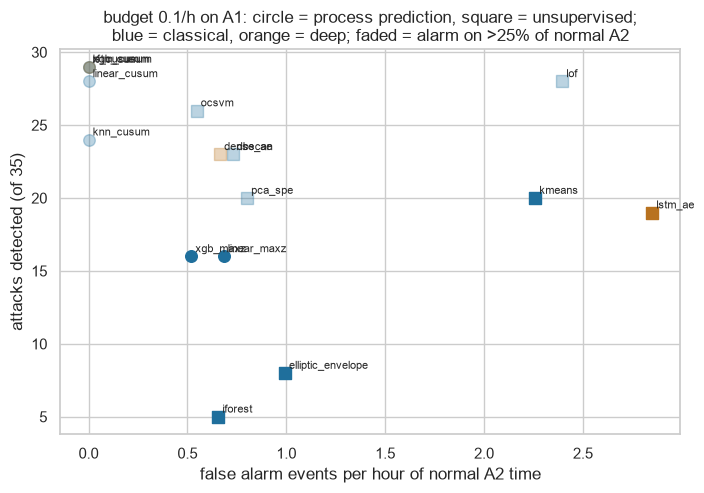

In [4]:
op = "budget_0.1"
t = table[[(op, "det"), (op, "FA/h"), (op, "duty")]].copy()
t.columns = ["detected", "false_alarms_per_h", "normal_duty"]
t["usable"] = t["normal_duty"] < 0.25
display(t.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
for (obj, fam, m), r in t.iterrows():
    ax.scatter(r["false_alarms_per_h"], r["detected"], s=70,
               marker="o" if obj == "predictive" else "s",
               color="#1F6F9C" if fam == "classical" else "#B8721F",
               alpha=1 if r["usable"] else 0.3)
    ax.annotate(m, (r["false_alarms_per_h"], r["detected"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("false alarm events per hour of normal A2 time")
ax.set_ylabel("attacks detected (of 35)")
ax.set_title("budget 0.1/h on A1: circle = process prediction, square = unsupervised;\n"
             "blue = classical, orange = deep; faded = alarm on >25% of normal A2")
plt.show()

## 4. Which attacks each detector catches (budget 0.1/h)

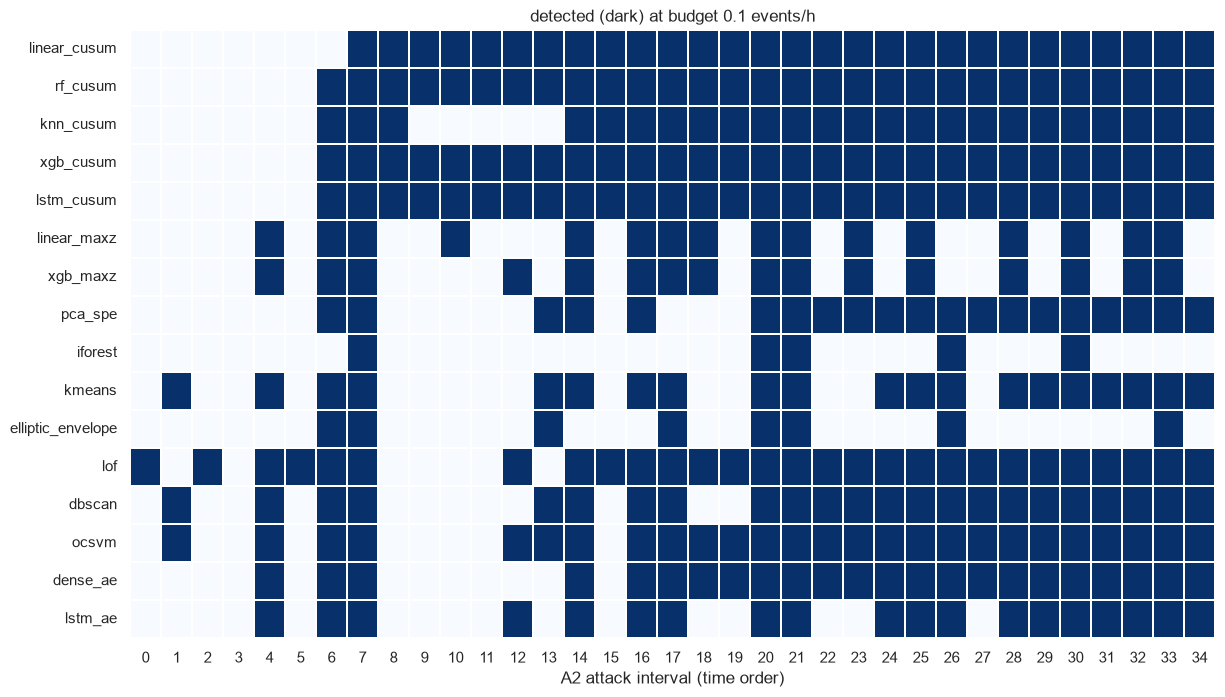

detected by no detector: [3]


In [5]:
det = {}
for r in res["runs"]:
    det[r["key"]] = {p["interval"]: float(p["detected"]) for p in r["operating_points"]["budget_0.1"]["per_interval"]}
heat = pd.DataFrame(det).T
fig, ax = plt.subplots(figsize=(14, 0.4 * len(heat) + 1.5))
sns.heatmap(heat, cmap="Blues", cbar=False, linewidths=0.3, linecolor="white", ax=ax)
ax.set_xlabel("A2 attack interval (time order)"); ax.set_title("detected (dark) at budget 0.1 events/h")
plt.show()
print("detected by no detector:", list(heat.columns[heat.sum() == 0]))

## 5. The process-prediction mapping

Linear-regression R^2 of each sensor on its chosen actuator inputs, on A1-fit
rows. Sensors below 0.5 are not explained by actuators and are left out of the
predictive arm; they are mostly the chemical analysers.

In [6]:
lin = next(r for r in res["runs"] if r["key"] == "linear_cusum")
mp = pd.DataFrame(lin["detector"]["mapping"]).T[["input_set", "fit_r2", "val_mse", "included"]]
mp.sort_values("fit_r2", ascending=False).round(3)

,input_set,fit_r2,val_mse,included
FIT201,all,0.994936,0.005477,True
FIT401,all,0.992587,0.023455,True
FIT501,all,0.992307,0.025272,True
FIT503,all,0.990973,0.018026,True
PIT501,all,0.980788,0.06521,True
FIT504,all,0.978901,0.014035,True
AIT504,stage,0.976498,0.021853,True
PIT503,all,0.975754,0.092996,True
FIT301,all,0.965927,0.034625,True
FIT502,all,0.963525,0.084857,True


## 6. Why the CUSUM detectors alarm continuously on A2: nominal drift

An accumulating CUSUM never forgets a persistent offset. Below: each
included sensor's mean standardised residual on A1-calibration and on
attack-free A2 rows, for the linear predictor. A sensor whose normal level
moved between A1 and A2 pushes CUSUM up without bound. This uses A2 only to
diagnose after the fact, never to choose anything.

In [7]:
from data import nominal_split
from nominal_models import NOMINAL_REGISTRY
split, _ = nominal_split()
lp = NOMINAL_REGISTRY["linear_maxz"](seed=42).fit(split)
names = [split.feature_names[i] for i in lp.targets]
z_cal = lp.residual_z(split.X_cal).mean(axis=0)
z_a2 = lp.residual_z(split.X_test)[split.y_test == 0].mean(axis=0)
drift = pd.DataFrame({"mean_z_A1_cal": z_cal, "mean_z_A2_normal": z_a2}, index=names)
drift["shift"] = drift["mean_z_A2_normal"] - drift["mean_z_A1_cal"]
drift.sort_values("shift", key=np.abs, ascending=False).round(2)

,mean_z_A1_cal,mean_z_A2_normal,shift
AIT501,-0.91,-9.75,-8.84
AIT504,0.26,3.13,2.87
AIT203,-0.02,-1.07,-1.06
FIT501,0.54,-0.13,-0.66
FIT401,0.53,-0.08,-0.61
FIT504,-0.46,-0.05,0.41
FIT502,0.45,0.10,-0.35
LIT401,-0.07,-0.30,-0.23
PIT501,-0.56,-0.38,0.18
FIT201,-0.08,0.06,0.14


## 7. Score timelines on A2 (from `--save-scores`)

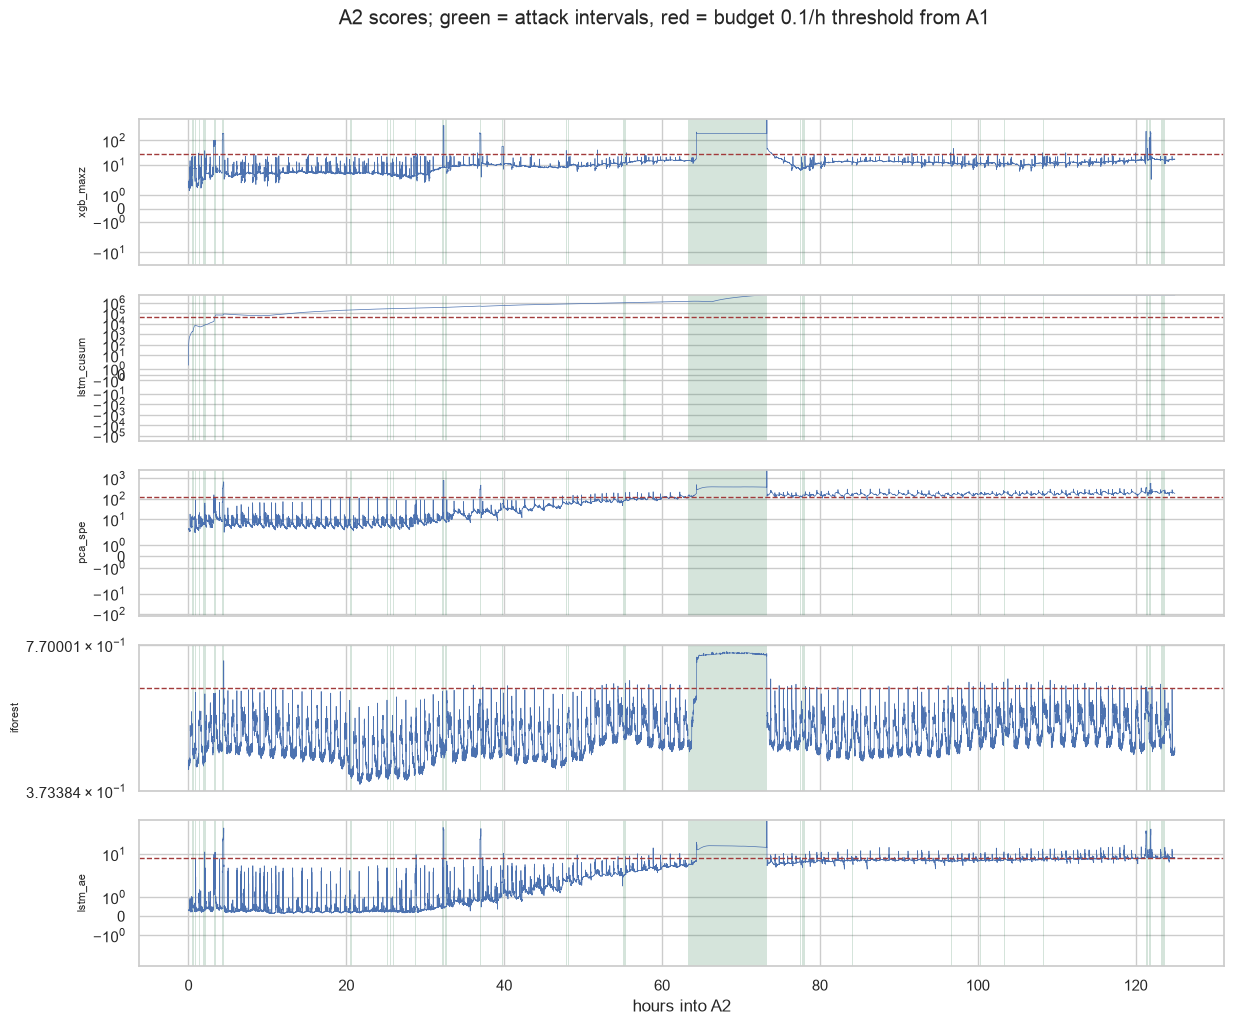

In [8]:
score_dirs = sorted(RESULTS.glob("a1a2-scores-*"), key=lambda p: p.stat().st_mtime)
if score_dirs:
    sd = score_dirs[-1]
    y = split.y_test
    show = [k for k in ("xgb_maxz", "lstm_cusum", "pca_spe", "iforest", "lstm_ae") if (sd / f"{k}-seed42.npy").exists()]
    fig, axes = plt.subplots(len(show), 1, figsize=(14, 2.2 * len(show)), sharex=True)
    for ax, k in zip(np.atleast_1d(axes), show):
        s = np.load(sd / f"{k}-seed42.npy")
        thr = next(r for r in res["runs"] if r["key"] == k)["operating_points"]["budget_0.1"]["threshold"]
        ax.plot(np.arange(len(s))[::10] / 3600, s[::10], lw=0.5)
        ax.axhline(thr, color="#A23B3B", ls="--", lw=1)
        starts = np.flatnonzero(np.diff(np.r_[0, y]) == 1); ends = np.flatnonzero(np.diff(np.r_[y, 0]) == -1)
        for a, b in zip(starts, ends):
            ax.axvspan(a / 3600, (b + 1) / 3600, color="#2F7A4F", alpha=0.2, lw=0)
        ax.set_ylabel(k, fontsize=8); ax.set_yscale("symlog")
    axes[-1].set_xlabel("hours into A2")
    plt.suptitle("A2 scores; green = attack intervals, red = budget 0.1/h threshold from A1"); plt.show()
else:
    print("no saved scores; run protocol.py with --save-scores")

## 8. Reporting boundaries

* One seed unless the run used `--seeds 5`; stochastic spread is then in the results file.
* "Detected" means any alarm event overlaps the annotated interval; no grace window after it ends.
* Attack intervals are contiguous runs of the A2 label (35). iTrust's official
  attack list, with attack points, is not in this repository.
* DAGMM, USAD, OmniAnomaly, TranAD and aCVAE are not implemented.
* Every number is computed from our own SWaT v0 files (sources in the data
  report); no published values are used.